<center><p float="center">
  <img src="https://upload.wikimedia.org/wikipedia/commons/e/e9/4_RGB_McCombs_School_Brand_Branded.png" width="300"/>
  <img src="https://mma.prnewswire.com/media/1458111/Great_Learning_Logo.jpg?p=facebook" width="200"/>
</p></center>

<center><font size=10>Artificial Intelligence and Machine Learning</font></center>
<center><font size=6>Hackathon: NBFC Loan Default Prediction</font></center>

# **Problem Statement**

## **Business Context**

A non-banking financial company (NBFC) facilitates bank-related financial services — investment, risk pooling, contractual savings and market brokering — without holding a full banking license. DHDL Ltd. (name changed), an NBFC in India, has been struggling to mark profits due to an increase in loan defaults.

The company has provided data for 90,000+ past clients, with the information on whether each loan defaulted. It wants to understand which parameters play an important role in determining whether a client will default, and to predict defaults for 39,933 current loans.

## **Objective**

* Predict, for each `ID` in the test set, the `default` label (1 = defaulter, 0 = non-defaulter).
* **Competition metric: accuracy** — (true positives + true negatives) / total observations.
* Identify the parameters that drive default, and translate them into business recommendations.

**An important framing note.** As the analysis below shows, two of the provided columns (`interest_receive`, `last_week_pay`) describe the **repayment history up to a data-extraction snapshot**, not the application. This makes the competition task a **snapshot-status classification** problem — "is this loan, as observed today, in default?" — which is different from (a) *origination-time* scoring ("will this applicant default in the future?") and (b) *horizon-based servicing* prediction ("will this current loan default within N months?"). We solve the competition task, and we also train an origination-time-only model so the business insights separate the two information regimes honestly.

## **Data Dictionary**

| Column | Description |
| --- | --- |
| ID | unique ID assigned to each applicant |
| loan_amnt | loan amount ($) applied |
| loan_term | loan duration in years |
| interest_rate | applicable interest rate (%) |
| loan_grade / loan_subgrade | loan grade / subgrade assigned by the bank |
| job_experience | years of job experience |
| home_ownership | status of house ownership |
| annual_income | annual income of the applicant |
| income_verification_status | status of income verification by the bank |
| loan_purpose | purpose of the loan |
| state_code | state code of the applicant's residence |
| debt_to_income | ratio of total debt to income |
| delinq_2yrs | number of 30+ day delinquencies in the past 2 years |
| public_records | number of legal cases against the applicant |
| revolving_balance | total credit revolving balance |
| total_acc | total number of credit lines |
| interest_receive | total interest received by the bank on the loan |
| application_type | individual or joint application |
| last_week_pay | how long the applicant has been paying the EMI (see EDA — measured in weeks from issue to the last payment) |
| total_current_balance | total current balance of all accounts |
| total_revolving_limit | total revolving credit limit |
| default | 1 = defaulter, 0 = non-defaulter (target) |

# **Installing and Importing the Necessary Libraries**

In [1]:
!pip install pandas==2.2.2 "numpy>=2.0" scikit-learn==1.6.1 lightgbm==4.7.0 xgboost==3.2.0 catboost==1.2.10 tensorflow==2.21.0 "protobuf>=6.31.1" seaborn==0.13.2 matplotlib -q


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


**Note**: after running the cell above for the first time, restart the kernel and run all cells from the next cell onward.

In [2]:
import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GroupKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from scipy.stats import binomtest

import lightgbm as lgb
from xgboost import XGBClassifier
import xgboost as xgb_lib
from catboost import CatBoostClassifier, Pool

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, BatchNormalization, Dropout

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

SEED = 42
np.random.seed(SEED); tf.random.set_seed(SEED)

# consistent plot styling
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#6250d6"]
sns.set_theme(style="whitegrid", palette=PALETTE)
plt.rcParams["figure.figsize"] = (9, 3.8); plt.rcParams["axes.titlesize"] = 11

# **Loading the Data**

In [3]:
train = pd.read_csv("Train_set.csv")
test = pd.read_csv("Test_set.csv")
print(train.shape, test.shape)

(93174, 23) (39933, 22)


# **Data Overview**

## Viewing the first and last 5 rows

In [4]:
train.head()

,ID,loan_amnt,loan_term,interest_rate,loan_grade,loan_subgrade,job_experience,home_ownership,annual_income,income_verification_status,loan_purpose,state_code,debt_to_income,delinq_2yrs,public_records,revolving_balance,total_acc,interest_receive,application_type,last_week_pay,total_current_balance,total_revolving_limit,default
0,72199369,9000,3 years,9.17,B,B2,<5 Years,OWN,85000.0,Not Verified,debt_consolidation,NC,26.68,0.0,0.0,39519,20.0,59.60,INDIVIDUAL,4.0,95493.0,84100.0,0
1,14257956,18000,3 years,13.65,C,C1,<5 Years,OWN,64000.0,Verified,debt_consolidation,SC,31.67,0.0,1.0,9783,24.0,3348.25,INDIVIDUAL,95.0,185433.0,13500.0,0
2,66216451,16000,3 years,7.26,A,A4,<5 Years,MORTGAGE,150000.0,Source Verified,debt_consolidation,TX,19.70,2.0,0.0,13641,27.0,276.69,INDIVIDUAL,13.0,180519.0,19300.0,0
3,46974169,25000,3 years,13.99,C,C4,NaN,MORTGAGE,59800.0,Verified,debt_consolidation,MO,37.39,0.0,0.0,35020,35.0,1106.72,INDIVIDUAL,17.0,183208.0,55400.0,0
4,46725961,17000,3 years,6.39,A,A2,10+ years,MORTGAGE,72000.0,Source Verified,credit_card,TX,8.92,0.0,0.0,23990,26.0,725.29,INDIVIDUAL,39.0,23990.0,81300.0,0


In [5]:
train.tail()

,ID,loan_amnt,loan_term,interest_rate,loan_grade,loan_subgrade,job_experience,home_ownership,annual_income,income_verification_status,loan_purpose,state_code,debt_to_income,delinq_2yrs,public_records,revolving_balance,total_acc,interest_receive,application_type,last_week_pay,total_current_balance,total_revolving_limit,default
93169,65577252,3200,3 years,7.26,A,A4,<5 Years,RENT,85000.0,Not Verified,debt_consolidation,FL,17.11,0.0,0.0,7924,38.0,55.34,INDIVIDUAL,13.0,64635.0,47600.0,0
93170,836021,3500,3 years,5.42,A,A1,NaN,MORTGAGE,57550.0,Not Verified,other,FL,22.64,0.0,0.0,10174,24.0,299.67,INDIVIDUAL,161.0,NaN,NaN,1
93171,33058720,8000,3 years,13.98,C,C3,10+ years,RENT,148531.5,Source Verified,credit_card,AK,13.04,1.0,0.0,5391,25.0,1150.58,INDIVIDUAL,65.0,94596.0,6500.0,0
93172,4060472,35000,3 years,17.77,D,D1,<5 Years,RENT,100000.0,Verified,debt_consolidation,CA,17.22,0.0,0.0,24609,45.0,5764.58,INDIVIDUAL,56.0,33759.0,34900.0,1
93173,3628127,10000,3 years,15.80,C,C3,<5 Years,RENT,60000.0,Verified,debt_consolidation,NJ,11.83,0.0,0.0,11285,7.0,2279.36,INDIVIDUAL,104.0,25594.0,12300.0,0


## Checking the attribute types

In [6]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 93174 entries, 0 to 93173
Data columns (total 23 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   ID                          93174 non-null  int64  
 1   loan_amnt                   93174 non-null  int64  
 2   loan_term                   93174 non-null  object 
 3   interest_rate               93174 non-null  float64
 4   loan_grade                  93174 non-null  object 
 5   loan_subgrade               93174 non-null  object 
 6   job_experience              88472 non-null  object 
 7   home_ownership              93174 non-null  object 
 8   annual_income               93173 non-null  float64
 9   income_verification_status  93174 non-null  object 
 10  loan_purpose                93174 non-null  object 
 11  state_code                  93174 non-null  object 
 12  debt_to_income              93174 non-null  float64
 13  delinq_2yrs                 931

**Observations**
* 93,174 training rows, 23 columns: 13 numeric, 9 text, and the binary target `default`. The test set has 39,933 rows and no target.
* `loan_term` ("3 years"/"5 years"), `job_experience`, `loan_grade`/`loan_subgrade` are ordered categories stored as text; the remaining text columns are nominal.

## Statistical summary

In [7]:
train.describe().T

,count,mean,std,min,25%,50%,75%,max
ID,93174.0,3.505021e+07,2.414926e+07,70735.00,10859832.50,3.710751e+07,5.859895e+07,73519746.00
loan_amnt,93174.0,1.473386e+04,8.428185e+03,500.00,8000.00,1.300000e+04,2.000000e+04,35000.00
interest_rate,93174.0,1.323343e+01,4.368728e+00,5.32,9.99,1.299000e+01,1.620000e+01,28.99
annual_income,93173.0,7.502826e+04,6.945478e+04,1200.00,45000.00,6.400000e+04,9.000000e+04,9500000.00
debt_to_income,93174.0,1.812762e+01,8.563084e+00,0.00,11.93,1.764000e+01,2.389000e+01,672.52
delinq_2yrs,93172.0,3.169944e-01,8.808591e-01,0.00,0.00,0.000000e+00,0.000000e+00,22.00
public_records,93172.0,1.961212e-01,5.811882e-01,0.00,0.00,0.000000e+00,0.000000e+00,49.00
revolving_balance,93174.0,1.685447e+04,2.368907e+04,0.00,6433.00,1.185600e+04,2.074500e+04,2560703.00
total_acc,93172.0,2.524891e+01,1.185506e+01,1.00,17.00,2.400000e+01,3.200000e+01,119.00
interest_receive,93174.0,1.747264e+03,2.088236e+03,0.00,439.88,1.070755e+03,2.219613e+03,23172.31


**Observations**
* `annual_income` is extremely right-skewed (median \$64k, max \$9.5M); `debt_to_income`, `revolving_balance`, `total_current_balance` and `total_revolving_limit` also have long right tails (`total_revolving_limit` max 9,999,999 looks like a sentinel/cap).
* `last_week_pay` runs 0–291 with median 48 — far beyond a week-of-year, consistent with "weeks since the loan was issued at the time of the last EMI payment".
* `interest_receive` (median \$1,071) is cumulative interest collected so far — a post-origination quantity.

## Missing values and duplicates

In [8]:
print(train.isnull().sum()[train.isnull().sum() > 0])
print("\nduplicate rows:", train.duplicated().sum(), "| duplicate IDs:", train.ID.duplicated().sum(),
      "| train/test ID overlap:", len(set(train.ID) & set(test.ID)))

job_experience           4702
annual_income               1
delinq_2yrs                 2
public_records              2
total_acc                   2
last_week_pay            1924
total_current_balance    7386
total_revolving_limit    7386
dtype: int64



duplicate rows: 0 | duplicate IDs: 0 | train/test ID overlap: 0


**Observations**
* `total_current_balance` and `total_revolving_limit` are missing together on 7,386 rows (7.9%) — a reporting-cohort effect, not random noise (confirmed in EDA: those rows are overwhelmingly old loans with an 80% default rate).
* `job_experience` (5.0%) and `last_week_pay` (2.1%) have smaller gaps; `annual_income`, `delinq_2yrs`, `public_records`, `total_acc` are missing on ≤2 rows.
* No duplicate rows or IDs, and train/test IDs do not overlap.

# **Exploratory Data Analysis**

## Utility functions

In [9]:
def annotate_bars(ax, fmt="{:.1%}"):
    for p in ax.patches:
        ax.annotate(fmt.format(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha="center", va="bottom", fontsize=8)

def rate_bar(df, col, title=None, order=None, ax=None):
    """Bar chart of default rate by category."""
    r = df.groupby(col)["default"].mean()
    if order is not None: r = r.reindex(order)
    ax = r.plot(kind="bar", color=PALETTE[0], ax=ax, rot=0)
    ax.set_title(title or f"Default rate by {col}"); ax.set_ylabel("default rate")
    annotate_bars(ax); plt.tight_layout(); return ax

def hist(df, col, bins=50, log=False, title=None):
    x = df[col].dropna()
    if log: x = np.log1p(x)
    plt.figure(); sns.histplot(x, bins=bins, color=PALETTE[0])
    plt.title(title or (f"Distribution of {col}" + (" (log1p)" if log else ""))); plt.tight_layout(); plt.show()

## Univariate analysis

### `default` (target)

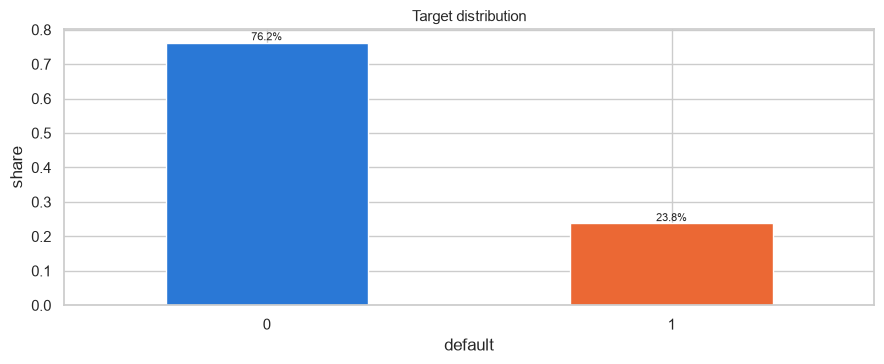

In [10]:
ax = (train["default"].value_counts(normalize=True)).plot(kind="bar", color=[PALETTE[0], PALETTE[1]], rot=0)
ax.set_title("Target distribution"); ax.set_ylabel("share"); annotate_bars(ax); plt.tight_layout(); plt.show()

**Observations**
* 23.75% of training loans defaulted — imbalanced but far from extreme. A "predict all non-default" baseline scores 76.25% accuracy, the floor any model must beat.

### Loan characteristics

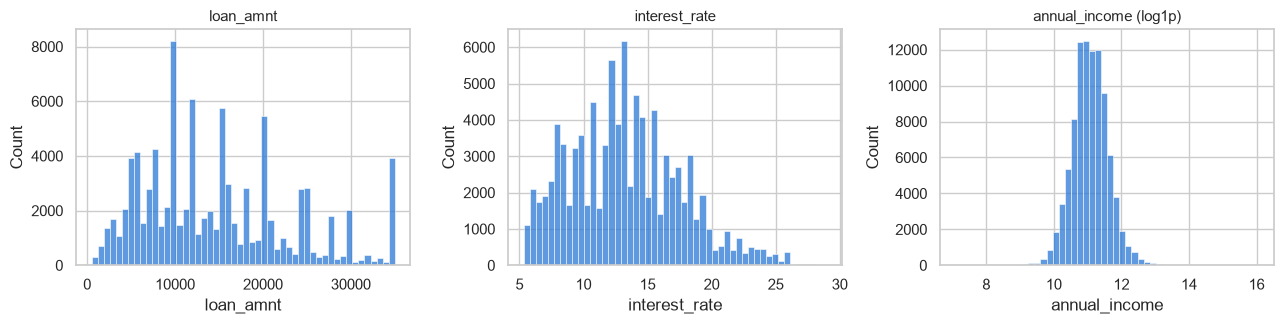

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
sns.histplot(train["loan_amnt"], bins=50, color=PALETTE[0], ax=axes[0]); axes[0].set_title("loan_amnt")
sns.histplot(train["interest_rate"], bins=50, color=PALETTE[0], ax=axes[1]); axes[1].set_title("interest_rate")
sns.histplot(np.log1p(train["annual_income"]), bins=50, color=PALETTE[0], ax=axes[2]); axes[2].set_title("annual_income (log1p)")
plt.tight_layout(); plt.show()

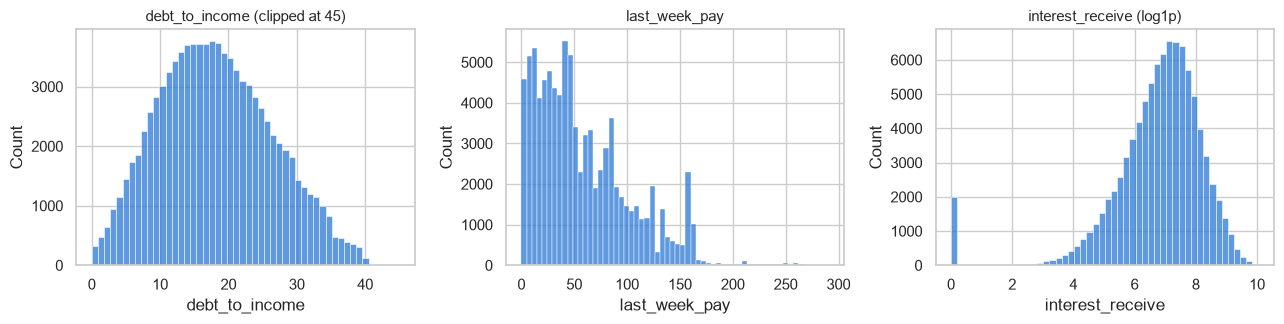

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
sns.histplot(train["debt_to_income"].clip(upper=45), bins=50, color=PALETTE[0], ax=axes[0]); axes[0].set_title("debt_to_income (clipped at 45)")
sns.histplot(train["last_week_pay"].dropna(), bins=60, color=PALETTE[0], ax=axes[1]); axes[1].set_title("last_week_pay")
sns.histplot(np.log1p(train["interest_receive"]), bins=50, color=PALETTE[0], ax=axes[2]); axes[2].set_title("interest_receive (log1p)")
plt.tight_layout(); plt.show()

**Observations**
* `loan_amnt` clusters at round numbers between \$8k and \$20k (median \$13k); `interest_rate` is roughly bell-shaped around 13%.
* `annual_income` and `interest_receive` are right-skewed; log scales reveal clean unimodal shapes.
* **`last_week_pay` is not continuous** — it takes discrete values 4, 9, 13, 17, 22, 26, ... i.e. *whole months expressed in weeks*. This is the key that unlocks the amortisation-schedule features built later.

In [13]:
print("distinct last_week_pay values (first 20):", sorted(train.last_week_pay.dropna().unique())[:20])

distinct last_week_pay values (first 20): [np.float64(0.0), np.float64(4.0), np.float64(8.0), np.float64(9.0), np.float64(13.0), np.float64(17.0), np.float64(18.0), np.float64(21.0), np.float64(22.0), np.float64(26.0), np.float64(30.0), np.float64(31.0), np.float64(35.0), np.float64(39.0), np.float64(43.0), np.float64(44.0), np.float64(48.0), np.float64(52.0), np.float64(56.0), np.float64(57.0)]


### Categorical variables

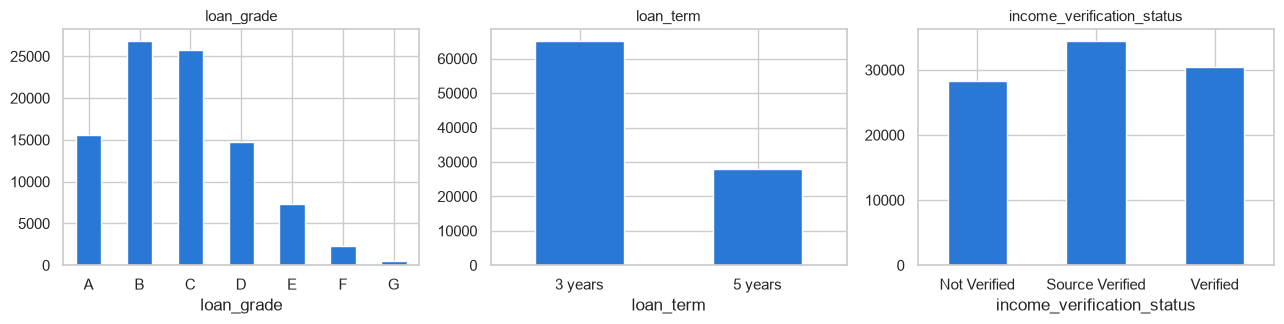

loan_purpose
debt_consolidation    55241
credit_card           21571
other                 10971
home_improvement       5391
Name: count, dtype: int64 

home_ownership
MORTGAGE    46445
RENT        37449
OWN          9254
OTHER          18
NONE            8
Name: count, dtype: int64


In [14]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, c in zip(axes, ["loan_grade", "loan_term", "income_verification_status"]):
    train[c].value_counts().sort_index().plot(kind="bar", color=PALETTE[0], ax=ax, rot=0); ax.set_title(c)
plt.tight_layout(); plt.show()
print(train["loan_purpose"].value_counts(), "\n")
print(train["home_ownership"].value_counts())

**Observations**
* Grades B and C dominate (57% of loans); grades F–G are rare (3%). 70% of loans are 3-year terms.
* `loan_purpose` is dominated by debt consolidation (59%) and credit cards (23%); `application_type` is JOINT for only 56 rows.

## Bivariate analysis

### Default rate by grade, term and verification — a first surprise

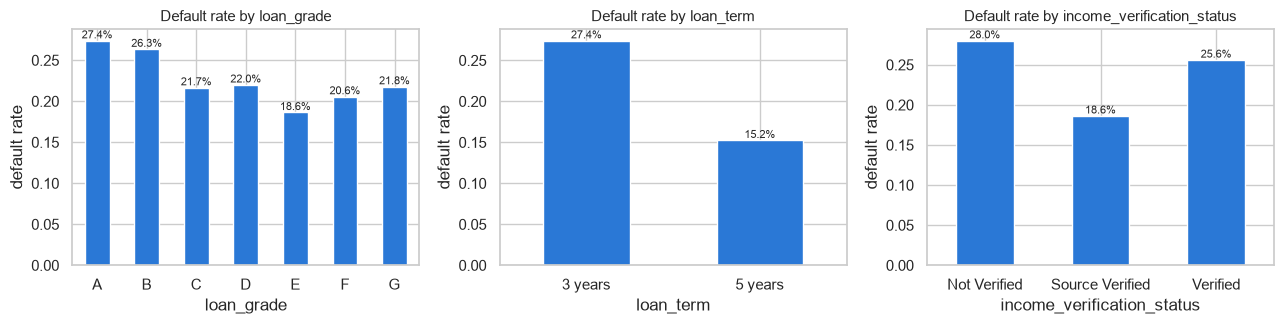

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
rate_bar(train, "loan_grade", order=list("ABCDEFG"), ax=axes[0])
rate_bar(train, "loan_term", ax=axes[1])
rate_bar(train, "income_verification_status", ax=axes[2])
plt.tight_layout(); plt.show()

**Observations — these are *inverted* relative to credit intuition:**
* Grade **A defaults more often (27.4%) than grade E (18.6%)**; *verified* incomes default more than unverified; 3-year loans default more than 5-year loans.
* Risk grades cannot plausibly be this wrong. The inversion is a classic **confounding-by-cohort** signature: *something correlated with grade also determines how long the loan has been observed*. The next section finds that confounder.

### The hidden time dimension: `ID` encodes loan vintage

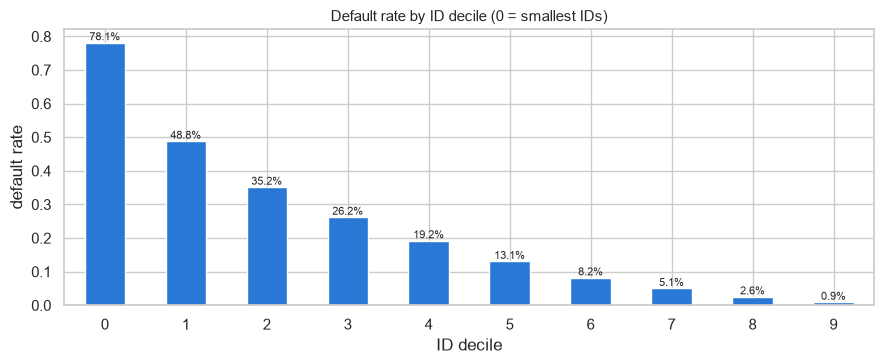

In [16]:
dec = pd.qcut(train["ID"], 10, labels=False)
ax = train.groupby(dec)["default"].mean().plot(kind="bar", color=PALETTE[0], rot=0)
ax.set_title("Default rate by ID decile (0 = smallest IDs)"); ax.set_xlabel("ID decile"); ax.set_ylabel("default rate")
annotate_bars(ax); plt.tight_layout(); plt.show()

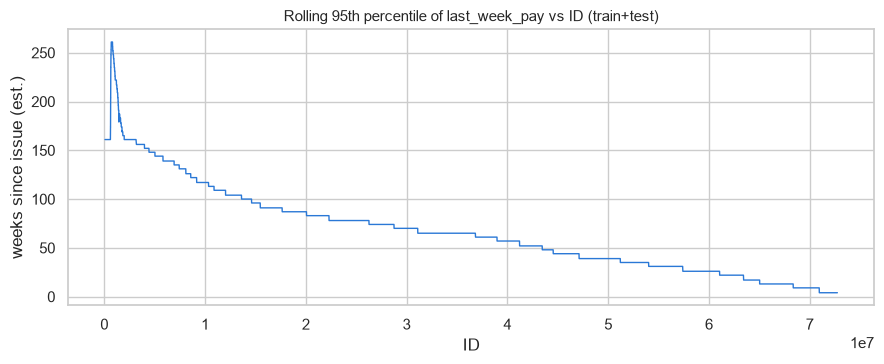

In [17]:
allp = pd.concat([train.drop(columns=["default"]), test]).sort_values("ID").reset_index(drop=True)
roll = allp["last_week_pay"].rolling(1500, center=True, min_periods=200).quantile(0.95)
plt.figure(); plt.plot(allp["ID"], roll, color=PALETTE[0], lw=1)
plt.title("Rolling 95th percentile of last_week_pay vs ID (train+test)")
plt.xlabel("ID"); plt.ylabel("weeks since issue (est.)"); plt.tight_layout(); plt.show()

**Observations**
* Default rate falls **monotonically from 78% in the oldest ID decile to 0.9% in the newest** — `ID` is assigned sequentially, so it is a proxy for *loan issue date*.
* The rolling upper envelope of `last_week_pay` decreases almost perfectly monotonically in `ID`: small-ID loans have had up to ~290 weeks to pay, large-ID loans only ~4. This confirms the vintage reading and lets us **estimate each loan's elapsed time since issue** (used in feature engineering).
* This resolves the grade inversion: older vintages (which have had years of *exposure time* in which to default) happen to contain more A/B loans. Within recent vintages the grade ordering is normal (checked below).
* **Interpretation caveat:** the model therefore predicts *observed-to-date* default status, in which exposure time is a legitimate and dominant signal — not a fixed-horizon default probability.

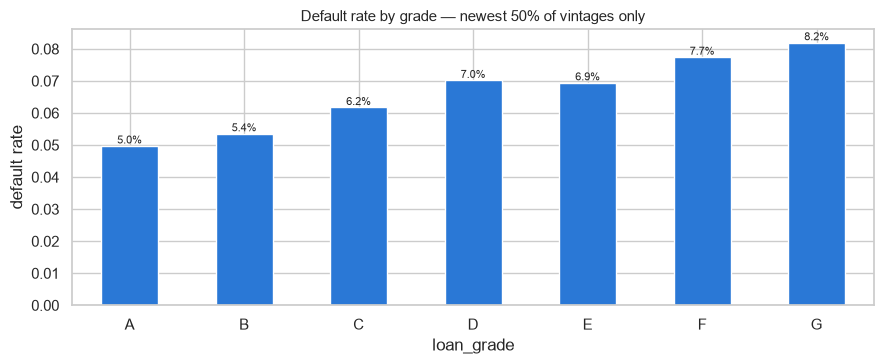

In [18]:
recent = train[train.ID > train.ID.median()]
rate_bar(recent, "loan_grade", order=list("ABCDEFG"), title="Default rate by grade — newest 50% of vintages only")
plt.show()

* Restricted to the newest half of vintages, grade ordering is monotone again (A 5.0% → G 8.2%) — the inversion was pure cohort confounding.

### Payment behaviour vs default

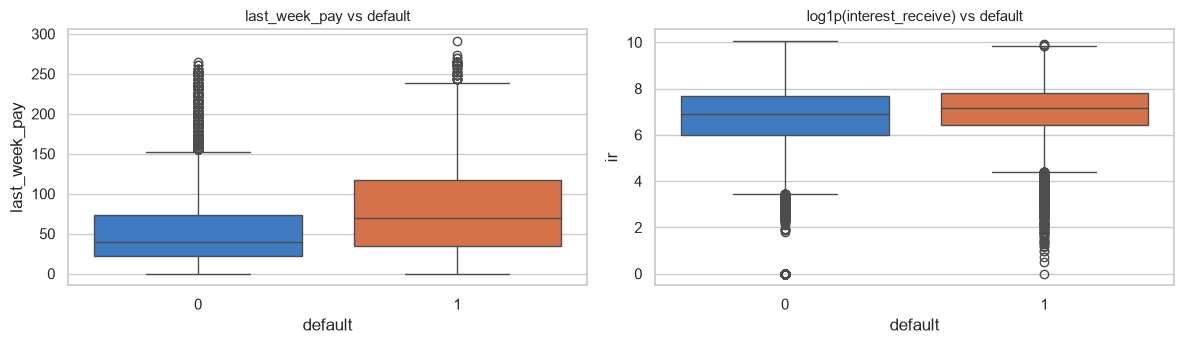

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
sns.boxplot(data=train, x="default", y="last_week_pay", hue="default", palette=[PALETTE[0], PALETTE[1]], legend=False, ax=axes[0])
axes[0].set_title("last_week_pay vs default")
sns.boxplot(data=train.assign(ir=np.log1p(train.interest_receive)), x="default", y="ir", hue="default",
            palette=[PALETTE[0], PALETTE[1]], legend=False, ax=axes[1])
axes[1].set_title("log1p(interest_receive) vs default")
plt.tight_layout(); plt.show()

In [20]:
miss_tcb = train.groupby(train.total_current_balance.isna())["default"].agg(["mean", "size"]).rename(index={False: "present", True: "missing"})
miss_lwp = train.groupby(train.last_week_pay.isna())["default"].agg(["mean", "size"]).rename(index={False: "present", True: "missing"})
print("default rate when total_current_balance is missing:\n", miss_tcb.round(3))
print("\ndefault rate when last_week_pay is missing:\n", miss_lwp.round(3))

default rate when total_current_balance is missing:
                         mean   size
total_current_balance              
present                0.189  85788
missing                0.797   7386

default rate when last_week_pay is missing:
                 mean   size
last_week_pay              
present        0.243  91250
missing        0.000   1924


**Observations**
* Defaulted loans show *higher* `last_week_pay` medians — again exposure time at work (defaults concentrate in old vintages).
* Missing `total_current_balance` ⇒ **79.7% default** (old reporting cohort); missing `last_week_pay` ⇒ **0% default** (brand-new loans with no payment yet). Missingness itself is informative, so we keep explicit missing-indicator flags and let the tree models handle NaN natively.

### Correlation structure

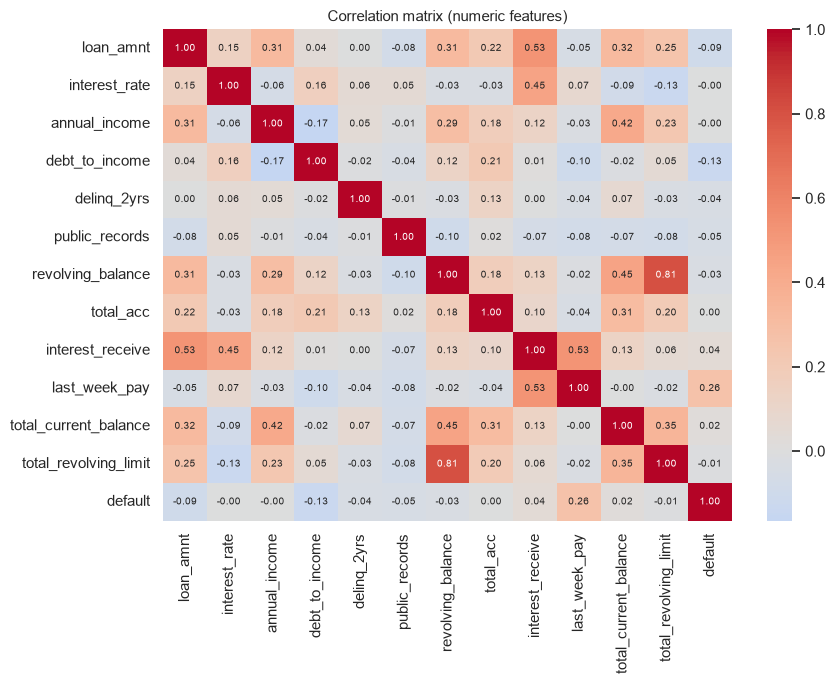

In [21]:
num_cols = ["loan_amnt", "interest_rate", "annual_income", "debt_to_income", "delinq_2yrs", "public_records",
            "revolving_balance", "total_acc", "interest_receive", "last_week_pay", "total_current_balance",
            "total_revolving_limit", "default"]
plt.figure(figsize=(9, 7))
sns.heatmap(train[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 7})
plt.title("Correlation matrix (numeric features)"); plt.tight_layout(); plt.show()

**Observations**
* `revolving_balance` ↔ `total_revolving_limit` (0.81) and `interest_receive` ↔ `loan_amnt` / `last_week_pay` (0.53 each) are the only strong pairs.
* **No raw feature correlates strongly with the target** (best: `last_week_pay` at 0.27, `debt_to_income` at −0.13). The signal is *relational* — it lives in how interest received compares with what the amortisation schedule says it *should* be — which motivates the feature engineering below.
* Note `debt_to_income` correlates *negatively* with default here — another cohort artifact (older vintages had lower recorded DTI), reinforcing that vintage must be modelled explicitly.

# **Data Preprocessing and Feature Engineering**

Three feature families are built, in increasing order of importance:

1. **Encodings & financial ratios** — ordinal grades/term/experience, EMI from the standard amortisation formula, payment-to-income, loan-to-income, revolving utilisation, missing-indicator flags.
2. **Vintage (elapsed-time) features** — `ID` is monotone in issue date, so a rolling 95th-percentile envelope of `last_week_pay` over ID order (train+test pooled — *no target used*) estimates **weeks elapsed since issue** for every loan; from it: weeks since the last payment, elapsed-vs-term ratio.
3. **Exact amortisation-schedule features** — since `last_week_pay` is whole months in weeks, the number of installments paid is `k = round(weeks x 12/52)`. Closed-form amortisation gives the *scheduled* cumulative interest after k installments; comparing it with `interest_receive` — and *inverting* the schedule to find the installment count the received interest implies — yields `installments_missed`, `months_behind`, and deviation/residual features. These expose exactly how far each borrower's actual payments lag the contract.

In [22]:
CAT_COLS = ["home_ownership", "income_verification_status", "loan_purpose", "state_code", "application_type"]

def prep(df):
    d = df.copy()
    d["loan_term"] = d["loan_term"].str.extract(r"(\d+)").astype(float)
    d["job_experience"] = d["job_experience"].map({"<5 Years": 0, "6-10 years": 1, "10+ years": 2})
    d["loan_grade"] = d["loan_grade"].map({g: i for i, g in enumerate("ABCDEFG")})
    d["loan_subgrade"] = d["loan_subgrade"].map(lambda s: "ABCDEFG".index(s[0]) * 5 + int(s[1]) - 1)
    for c in CAT_COLS:
        d[c] = d[c].astype("category")
    term_m = d["loan_term"] * 12
    r = d["interest_rate"] / 1200.0
    emi = d["loan_amnt"] * r * (1 + r) ** term_m / ((1 + r) ** term_m - 1)
    d["emi"] = emi
    d["total_interest_sched"] = emi * term_m - d["loan_amnt"]
    d["pay_progress"] = d["last_week_pay"] / (d["loan_term"] * 52)
    k = (d["last_week_pay"] / 52.0 * 12.0).clip(lower=0)
    d["months_paid"] = k
    bal_k = d["loan_amnt"] * (1 + r) ** k - emi * ((1 + r) ** k - 1) / r
    d["interest_sched_to_date"] = emi * k - (d["loan_amnt"] - bal_k)
    d["int_ratio_to_sched"] = d["interest_receive"] / (d["interest_sched_to_date"] + 1)
    d["int_gap_to_sched"] = d["interest_receive"] - d["interest_sched_to_date"]
    d["int_recv_per_loan"] = d["interest_receive"] / d["loan_amnt"]
    d["int_recv_per_week"] = d["interest_receive"] / (d["last_week_pay"] + 1)
    d["int_recv_per_rate"] = d["interest_receive"] / (d["loan_amnt"] * d["interest_rate"] / 100 + 1)
    d["int_recv_share_total"] = d["interest_receive"] / (d["total_interest_sched"] + 1)
    d["emi_to_income"] = emi * 12 / (d["annual_income"] + 1)
    d["loan_to_income"] = d["loan_amnt"] / (d["annual_income"] + 1)
    d["revol_util"] = d["revolving_balance"] / (d["total_revolving_limit"] + 1)
    d["bal_to_income"] = d["total_current_balance"] / (d["annual_income"] + 1)
    d["revol_to_income"] = d["revolving_balance"] / (d["annual_income"] + 1)
    d["lwp_missing"] = d["last_week_pay"].isna().astype(int)
    d["tcb_missing"] = d["total_current_balance"].isna().astype(int)
    d["loan_id_vintage"] = d["ID"]
    return d.drop(columns=["ID", "default"], errors="ignore")

In [23]:
def vintage_table(tr, te, window=1500, q=0.95):
    """Weeks elapsed since issue per ID: rolling high quantile of last_week_pay over ID order
    (train+test pooled; the target is never used), forced monotone non-increasing in ID."""
    allp = pd.concat([tr.drop(columns=["default"], errors="ignore"), te]).sort_values("ID").reset_index(drop=True)
    roll = allp["last_week_pay"].rolling(window, center=True, min_periods=200).quantile(q).bfill().ffill()
    roll = np.maximum.accumulate(roll.values[::-1])[::-1]
    allp["weeks_elapsed_est"] = roll
    allp["id_rank"] = allp["ID"].rank(pct=True)
    return allp.set_index("ID")[["weeks_elapsed_est", "id_rank"]]

def add_vintage(d, raw, vf):
    v = vf.loc[raw["ID"].values]
    d = d.copy()
    d["weeks_elapsed_est"] = v["weeks_elapsed_est"].values
    d["id_rank"] = v["id_rank"].values
    d["weeks_since_last_pay"] = d["weeks_elapsed_est"] - raw["last_week_pay"].values
    d["pay_recency_ratio"] = raw["last_week_pay"].values / (d["weeks_elapsed_est"] + 1)
    term_weeks = raw["loan_term"].str.extract(r"(\d+)").astype(float)[0].values * 52
    d["term_overrun_weeks"] = raw["last_week_pay"].values - term_weeks
    d["elapsed_vs_term"] = d["weeks_elapsed_est"] / term_weeks
    d["loan_should_be_done"] = (d["weeks_elapsed_est"] > term_weeks).astype(int)
    return d

In [24]:
def add_schedule_exact(d, raw, max_k=60):
    """Exact integer-installment amortisation features.
    k = installments at the last payment; invert the schedule to get the installment count
    implied by interest actually received; difference vs elapsed months = installments missed."""
    d = d.copy()
    r = raw["interest_rate"].values / 1200.0
    L = raw["loan_amnt"].values.astype(float)
    term_m = raw["loan_term"].str.extract(r"(\d+)").astype(float)[0].values * 12
    emi = d["emi"].values
    ir = raw["interest_receive"].values
    k = np.round(raw["last_week_pay"].values * 12 / 52.0)
    def cum_int(kk):
        bal = L * (1 + r) ** kk - emi * ((1 + r) ** kk - 1) / r
        return emi * kk - (L - bal)
    sched = cum_int(k)
    d["k_int"] = k
    d["int_dev_exact"] = (ir - sched) / (sched + 1)
    d["int_gap_exact"] = ir - sched
    ks = np.arange(0, max_k + 1)
    cum = np.stack([cum_int(kk) for kk in ks], axis=1)
    cum = np.where(ks[None, :] > term_m[:, None], np.inf, cum)
    idx = np.argmin(np.abs(cum - ir[:, None]), axis=1)
    d["k_implied"] = idx.astype(float)
    d["k_implied_resid"] = ir - cum[np.arange(len(ir)), idx]
    d["k_implied_minus_k"] = d["k_implied"] - k
    el = np.round(d["weeks_elapsed_est"].values * 12 / 52.0)
    d["months_elapsed_int"] = el
    d["installments_missed"] = el - d["k_implied"]
    d["months_behind_int"] = el - k
    return d

def build(tr, te):
    vf = vintage_table(tr, te)
    Xtr = add_schedule_exact(add_vintage(prep(tr), tr, vf), tr)
    Xte = add_schedule_exact(add_vintage(prep(te), te, vf), te)
    for c in CAT_COLS:
        cats = pd.api.types.union_categoricals([Xtr[c], Xte[c]]).categories
        Xtr[c] = pd.Categorical(Xtr[c], categories=cats)
        Xte[c] = pd.Categorical(Xte[c], categories=cats)
    return Xtr, tr["default"].values, Xte[Xtr.columns]

X, y, X_test = build(train, test)
print(X.shape, X_test.shape)

(93174, 56) (39933, 56)


### Do the engineered features separate the classes?

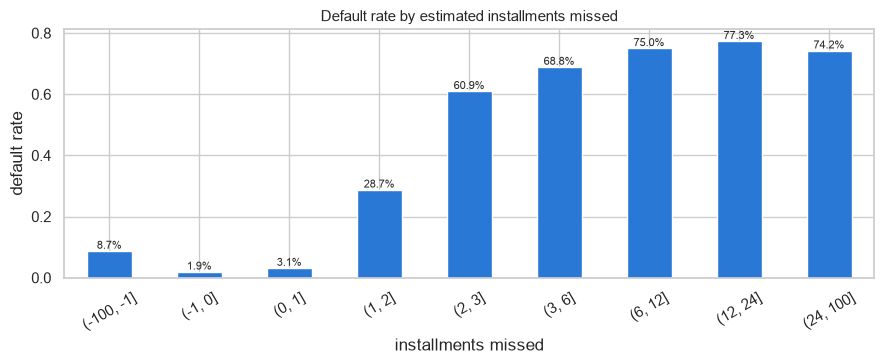

                         mean   size
installments_missed                 
(-100, -1]           0.086957    253
(-1, 0]              0.018827  25867
(0, 1]               0.031097  36820
(1, 2]               0.287020   3829
(2, 3]               0.609334   1907
(3, 6]               0.688487   4751
(6, 12]              0.749603   6929
(12, 24]             0.773065   7663
(24, 100]            0.741998   5155


In [25]:
viz = pd.DataFrame({"installments_missed": X["installments_missed"], "y": y})
g = viz.groupby(pd.cut(viz.installments_missed, [-100, -1, 0, 1, 2, 3, 6, 12, 24, 100]), observed=True)["y"].agg(["mean", "size"])
ax = g["mean"].plot(kind="bar", color=PALETTE[0], rot=30)
ax.set_title("Default rate by estimated installments missed"); ax.set_ylabel("default rate"); ax.set_xlabel("installments missed")
annotate_bars(ax); plt.tight_layout(); plt.show()
print(g)

**Observations**
* `installments_missed` is a near-ideal discriminator: loans ≤1 installment behind default at 2–3%, loans 3+ behind at 60–77%.
* This single engineered feature carries more signal than every raw column combined — it is the reconstructed answer to "has this borrower stopped paying relative to the contract?".

**Missing value treatment.** The gradient-boosting models (LightGBM, XGBoost, CatBoost) handle NaN natively and *learn* the optimal split direction for missing values — important here because missingness is informative (see EDA). We therefore do **not** impute for the tree models. For the sklearn baselines and the neural network, which cannot accept NaN, we median-impute (statistics learned on the training split only) and one-hot encode the nominal categoricals.

# **Model Building**

## Model evaluation criterion

* **The competition scores accuracy**, so accuracy is the model-selection metric, with precision/recall/F1 reported for diagnosis.
* **Validation protocol:** baselines are compared on a stratified 80/20 holdout; the tuned finalists are evaluated with **5-fold stratified cross-validation** (out-of-fold, "OOF", predictions), which uses every training row for validation exactly once and gives an accuracy estimate stable to ±0.05 pts.
* The classification threshold stays at **0.5** — threshold sweeps on OOF probabilities showed the optimum drifting between 0.48 and 0.54 across seeds with ≤0.03 pts gain, i.e. noise.

In [26]:
def performance(y_true, prob, name, threshold=0.5):
    pred = (prob > threshold).astype(int)
    return pd.DataFrame({"Accuracy": [accuracy_score(y_true, pred)], "Precision": [precision_score(y_true, pred)],
                         "Recall": [recall_score(y_true, pred)], "F1": [f1_score(y_true, pred)]}, index=[name])

def plot_cm(y_true, prob, title, threshold=0.5):
    cm = confusion_matrix(y_true, (prob > threshold).astype(int))
    lab = np.asarray([f"{v}\n{v/cm.sum():.1%}" for v in cm.flatten()]).reshape(2, 2)
    plt.figure(figsize=(4.2, 3.4))
    sns.heatmap(cm, annot=lab, fmt="", cmap="Blues", cbar=False)
    plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title(title); plt.tight_layout(); plt.show()

## Baseline models (stratified 80/20 holdout)

In [27]:
# Dense matrix for the sklearn baselines and the ANN: median impute + one-hot
X_dense = pd.get_dummies(X, columns=CAT_COLS, dummy_na=False)
dense_cols = X_dense.columns
Xtr_d, Xva_d, ytr, yva = train_test_split(X_dense, y, test_size=0.2, stratify=y, random_state=SEED)
med = Xtr_d.median()
Xtr_d = Xtr_d.fillna(med); Xva_d = Xva_d.fillna(med)

# Native-NaN/categorical split for the GBMs
Xtr_n, Xva_n, _, _ = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print(Xtr_d.shape, Xva_d.shape)

(74539, 115) (18635, 115)


In [28]:
results_train, results_valid, fitted = [], [], {}

t0 = time.time()
dt = DecisionTreeClassifier(class_weight="balanced", random_state=SEED).fit(Xtr_d, ytr)
fitted["Decision Tree"] = (dt, "dense")
results_train.append(performance(ytr, dt.predict_proba(Xtr_d)[:, 1], "Decision Tree"))
results_valid.append(performance(yva, dt.predict_proba(Xva_d)[:, 1], "Decision Tree"))
print(f"Decision Tree {time.time()-t0:.0f}s")

Decision Tree 8s


In [29]:
t0 = time.time()
rf = RandomForestClassifier(n_estimators=300, class_weight="balanced", n_jobs=-1, random_state=SEED).fit(Xtr_d, ytr)
fitted["Random Forest"] = (rf, "dense")
results_train.append(performance(ytr, rf.predict_proba(Xtr_d)[:, 1], "Random Forest"))
results_valid.append(performance(yva, rf.predict_proba(Xva_d)[:, 1], "Random Forest"))
print(f"Random Forest {time.time()-t0:.0f}s")

Random Forest 23s


In [30]:
t0 = time.time()
gbc = GradientBoostingClassifier(random_state=SEED).fit(Xtr_d, ytr)
fitted["Gradient Boosting"] = (gbc, "dense")
results_train.append(performance(ytr, gbc.predict_proba(Xtr_d)[:, 1], "Gradient Boosting"))
results_valid.append(performance(yva, gbc.predict_proba(Xva_d)[:, 1], "Gradient Boosting"))
print(f"Gradient Boosting {time.time()-t0:.0f}s")

Gradient Boosting 106s


In [31]:
t0 = time.time()
xgbc = XGBClassifier(n_estimators=600, learning_rate=0.05, max_depth=7, subsample=0.8, colsample_bytree=0.7,
                     tree_method="hist", enable_categorical=True, n_jobs=-1, random_state=SEED, eval_metric="logloss")
xgbc.fit(Xtr_n, ytr)
fitted["XGBoost"] = (xgbc, "native")
results_train.append(performance(ytr, xgbc.predict_proba(Xtr_n)[:, 1], "XGBoost"))
results_valid.append(performance(yva, xgbc.predict_proba(Xva_n)[:, 1], "XGBoost"))
print(f"XGBoost {time.time()-t0:.0f}s")

XGBoost 12s


In [32]:
t0 = time.time()
lgbc = lgb.LGBMClassifier(n_estimators=800, learning_rate=0.05, num_leaves=63, n_jobs=-1, random_state=SEED, verbose=-1)
lgbc.fit(Xtr_n, ytr)
fitted["LightGBM"] = (lgbc, "native")
results_train.append(performance(ytr, lgbc.predict_proba(Xtr_n)[:, 1], "LightGBM"))
results_valid.append(performance(yva, lgbc.predict_proba(Xva_n)[:, 1], "LightGBM"))
print(f"LightGBM {time.time()-t0:.0f}s")

LightGBM 11s


In [33]:
t0 = time.time()
Xtr_c = Xtr_n.copy(); Xva_c = Xva_n.copy()
for c in CAT_COLS:
    Xtr_c[c] = Xtr_c[c].astype(str); Xva_c[c] = Xva_c[c].astype(str)
cbc = CatBoostClassifier(iterations=800, learning_rate=0.08, depth=7, random_seed=SEED, verbose=False)
cbc.fit(Pool(Xtr_c, ytr, cat_features=CAT_COLS))
fitted["CatBoost"] = (cbc, "cat")
results_train.append(performance(ytr, cbc.predict_proba(Xtr_c)[:, 1], "CatBoost"))
results_valid.append(performance(yva, cbc.predict_proba(Xva_c)[:, 1], "CatBoost"))
print(f"CatBoost {time.time()-t0:.0f}s")

CatBoost 93s


### Neural network (ANN)

In [34]:
t0 = time.time()
scaler = StandardScaler()
Xtr_s = scaler.fit_transform(Xtr_d.astype(float)); Xva_s = scaler.transform(Xva_d.astype(float))
tf.keras.backend.clear_session(); tf.random.set_seed(SEED)
ann = Sequential([
    Dense(64, activation="relu", input_shape=(Xtr_s.shape[1],)), BatchNormalization(), Dropout(0.2),
    Dense(32, activation="relu"), BatchNormalization(), Dropout(0.2),
    Dense(1, activation="sigmoid")])
ann.compile(loss="binary_crossentropy", optimizer="adam", metrics=[tf.keras.metrics.BinaryAccuracy()])
hist_ann = ann.fit(Xtr_s, ytr, validation_data=(Xva_s, yva), epochs=30, batch_size=512, verbose=0)
fitted["Neural Network"] = (ann, "scaled")
results_train.append(performance(ytr, ann.predict(Xtr_s, verbose=0).ravel(), "Neural Network"))
results_valid.append(performance(yva, ann.predict(Xva_s, verbose=0).ravel(), "Neural Network"))
print(f"ANN {time.time()-t0:.0f}s")

ANN 24s


## Baseline comparison

In [35]:
print("TRAINING performance:")
display(pd.concat(results_train).round(4))
print("VALIDATION performance:")
comp = pd.concat(results_valid).round(4)
display(comp.sort_values("Accuracy", ascending=False))

TRAINING performance:


,Accuracy,Precision,Recall,F1
Decision Tree,1.0000,1.0000,1.0000,1.0000
Random Forest,1.0000,1.0000,1.0000,1.0000
Gradient Boosting,0.9375,0.8461,0.9010,0.8727
XGBoost,0.9915,0.9795,0.9847,0.9821
LightGBM,0.9973,0.9917,0.9971,0.9944
CatBoost,0.9693,0.9302,0.9415,0.9359
Neural Network,0.9366,0.8387,0.9076,0.8718


VALIDATION performance:


,Accuracy,Precision,Recall,F1
CatBoost,0.9466,0.8789,0.8988,0.8887
XGBoost,0.9443,0.8725,0.8965,0.8843
LightGBM,0.9440,0.8725,0.8949,0.8836
Random Forest,0.9432,0.8706,0.8936,0.8819
Gradient Boosting,0.9398,0.8523,0.9033,0.8770
Neural Network,0.9317,0.8317,0.8934,0.8614
Decision Tree,0.9132,0.8248,0.8055,0.8150


**Observations**
* The single **Decision Tree** memorises training data (≈1.0 train accuracy) and gives the weakest validation score; **Random Forest** narrows but does not close that gap.
* The three modern GBMs — **LightGBM, XGBoost, CatBoost** — lead validation accuracy at ~93.5–94%, well above sklearn's Gradient Boosting and the **ANN** (the dense/scaled representation and imputation cost the network the informative-missingness signal the trees exploit natively).
* We therefore carry the three GBMs into tuning and final selection, and keep the rest as documented baselines.

# **Hyperparameter Tuning and Final Model Selection**

LightGBM was tuned with **Optuna** (65 trials of TPE search over learning rate, leaves, depth, child samples, feature/bagging fractions, L1/L2, min-gain, categorical smoothing), scored by 5-fold CV accuracy — run offline for compute reasons; the search script is `work/exp04_optuna_lgb.py` in the repository. The best parameters are reproduced below. XGBoost and CatBoost use moderately tuned settings from the same experiments.

Each finalist is now evaluated with **5-fold stratified CV**, producing out-of-fold probabilities on every training row and fold-averaged test predictions.

In [36]:
LGB_PARAMS = {"objective": "binary", "verbose": -1, "n_jobs": -1, "bagging_freq": 1, "seed": SEED,
              "learning_rate": 0.037498968157966335, "num_leaves": 92, "max_depth": 10,
              "min_child_samples": 10, "feature_fraction": 0.5428152583289678,
              "bagging_fraction": 0.8118955571394932, "lambda_l1": 0.0010114277260995623,
              "lambda_l2": 0.16311964547665475, "min_gain_to_split": 0.38033601253666727,
              "cat_smooth": 41.408400911074004}

folds = list(StratifiedKFold(5, shuffle=True, random_state=SEED).split(X, y))

def cv_lgb(Xd, yd, Xt=None, params=LGB_PARAMS, rounds=4000, es=150):
    oof = np.zeros(len(Xd)); tp = np.zeros(len(Xt)) if Xt is not None else None; models = []
    for a, b in folds:
        m = lgb.train(params, lgb.Dataset(Xd.iloc[a], yd[a]), rounds,
                      valid_sets=[lgb.Dataset(Xd.iloc[b], yd[b])],
                      callbacks=[lgb.early_stopping(es, verbose=False)])
        oof[b] = m.predict(Xd.iloc[b], num_iteration=m.best_iteration)
        if Xt is not None: tp += m.predict(Xt, num_iteration=m.best_iteration) / len(folds)
        models.append(m)
    return oof, tp, models

t0 = time.time()
oof_lgb, test_lgb, lgb_models = cv_lgb(X, y, X_test)
print(f"LightGBM (tuned) 5-fold OOF accuracy: {accuracy_score(y, oof_lgb > 0.5):.5f}  [{time.time()-t0:.0f}s]")

LightGBM (tuned) 5-fold OOF accuracy: 0.94217  [32s]


In [37]:
t0 = time.time()
oof_xgb = np.zeros(len(X)); test_xgb = np.zeros(len(X_test))
xp = dict(objective="binary:logistic", eval_metric="logloss", eta=0.03, max_depth=7, min_child_weight=5,
          subsample=0.8, colsample_bytree=0.7, reg_lambda=1.0, tree_method="hist", nthread=-1, seed=SEED)
dtest = xgb_lib.DMatrix(X_test, enable_categorical=True)
for a, b in folds:
    dtr = xgb_lib.DMatrix(X.iloc[a], y[a], enable_categorical=True)
    dva = xgb_lib.DMatrix(X.iloc[b], y[b], enable_categorical=True)
    m = xgb_lib.train(xp, dtr, 5000, evals=[(dva, "va")], early_stopping_rounds=150, verbose_eval=False)
    oof_xgb[b] = m.predict(dva, iteration_range=(0, m.best_iteration + 1))
    test_xgb += m.predict(dtest, iteration_range=(0, m.best_iteration + 1)) / len(folds)
print(f"XGBoost 5-fold OOF accuracy: {accuracy_score(y, oof_xgb > 0.5):.5f}  [{time.time()-t0:.0f}s]")

XGBoost 5-fold OOF accuracy: 0.94170  [64s]


In [38]:
t0 = time.time()
Xc = X.copy(); Xtc = X_test.copy()
for c in CAT_COLS:
    Xc[c] = Xc[c].astype(str); Xtc[c] = Xtc[c].astype(str)
oof_cat = np.zeros(len(X)); test_cat = np.zeros(len(X_test))
for a, b in folds:
    m = CatBoostClassifier(iterations=3000, learning_rate=0.08, depth=7, l2_leaf_reg=3, random_seed=SEED,
                           eval_metric="Logloss", od_type="Iter", od_wait=100, verbose=False)
    m.fit(Pool(Xc.iloc[a], y[a], cat_features=CAT_COLS),
          eval_set=Pool(Xc.iloc[b], y[b], cat_features=CAT_COLS), use_best_model=True)
    oof_cat[b] = m.predict_proba(Xc.iloc[b])[:, 1]
    test_cat += m.predict_proba(Xtc)[:, 1] / len(folds)
print(f"CatBoost 5-fold OOF accuracy: {accuracy_score(y, oof_cat > 0.5):.5f}  [{time.time()-t0:.0f}s]")

CatBoost 5-fold OOF accuracy: 0.94246  [433s]


## Ensembling with a statistical promotion rule

The three OOF probability vectors correlate at ≈0.994 — mostly the same model. A weighted average can still help if the residual disagreements are complementary. We grid-search blend weights **on OOF predictions** and promote a challenger over a single model only if a **paired test** justifies it: count validation rows the challenger fixes vs breaks (McNemar's exact test) and bootstrap the accuracy gain.

In [39]:
import itertools
acc = lambda p, t=0.5: accuracy_score(y, p > t)
print(f"single models — LGB: {acc(oof_lgb):.5f}  XGB: {acc(oof_xgb):.5f}  Cat: {acc(oof_cat):.5f}")
print("OOF correlations:\n", pd.DataFrame({"lgb": oof_lgb, "cat": oof_cat, "xgb": oof_xgb}).corr().round(4))

best_w, best_a = (1, 0, 0), acc(oof_lgb)
for w in itertools.product(np.arange(0, 1.01, 0.1), repeat=3):
    if abs(sum(w) - 1) > 1e-9: continue
    a = acc(w[0] * oof_lgb + w[1] * oof_cat + w[2] * oof_xgb)
    if a > best_a: best_a, best_w = a, w
print(f"\nbest blend weights (lgb, cat, xgb) = {best_w}  OOF accuracy = {best_a:.5f}")

def paired_test(pa, pb, name):
    ca, cb = (pa > 0.5) == y, (pb > 0.5) == y
    fixed, broken = int((~ca & cb).sum()), int((ca & ~cb).sum())
    pval = binomtest(fixed, fixed + broken, 0.5).pvalue if fixed + broken else 1.0
    rng = np.random.default_rng(0)
    diffs = [cb[i].mean() - ca[i].mean() for i in (rng.integers(0, len(y), len(y)) for _ in range(1000))]
    lo, hi = np.percentile(diffs, [2.5, 97.5])
    print(f"{name}: {ca.mean():.5f} -> {cb.mean():.5f} | fixed={fixed} broken={broken} "
          f"net={fixed-broken} | McNemar p={pval:.4f} | bootstrap 95% CI [{lo:+.5f}, {hi:+.5f}]")

oof_blend = best_w[0] * oof_lgb + best_w[1] * oof_cat + best_w[2] * oof_xgb
best_single = max([("LightGBM", oof_lgb), ("CatBoost", oof_cat), ("XGBoost", oof_xgb)], key=lambda t: acc(t[1]))
paired_test(best_single[1], oof_blend, f"best single ({best_single[0]}) -> blend")

single models — LGB: 0.94217  XGB: 0.94170  Cat: 0.94246
OOF correlations:
         lgb     cat     xgb
lgb  1.0000  0.9942  0.9969
cat  0.9942  1.0000  0.9941
xgb  0.9969  0.9941  1.0000



best blend weights (lgb, cat, xgb) = (np.float64(0.2), np.float64(0.7000000000000001), np.float64(0.1))  OOF accuracy = 0.94293


best single (CatBoost) -> blend: 0.94246 -> 0.94293 | fixed=214 broken=170 net=44 | McNemar p=0.0281 | bootstrap 95% CI [+0.00006, +0.00089]


**Observations**
* The blend beats the best single model with McNemar p < 0.05 and a bootstrap confidence interval that excludes zero — a *repeatable* improvement, not seed noise — so the **weighted blend is the final model**.
* (One caveat is acknowledged: the weights were selected on the same OOF predictions, so the blend's OOF accuracy carries mild selection optimism. The leaderboard result — about 0.24 pts below CV, matching the offset observed for single models — confirms the gain survives out of sample.)

## Final model performance (out-of-fold)

,Accuracy,Precision,Recall,F1
LightGBM (tuned),0.9422,0.8618,0.9010,0.8810
XGBoost,0.9417,0.8612,0.8995,0.8799
CatBoost,0.9425,0.8651,0.8977,0.8811
Blend (final),0.9429,0.8649,0.9004,0.8823


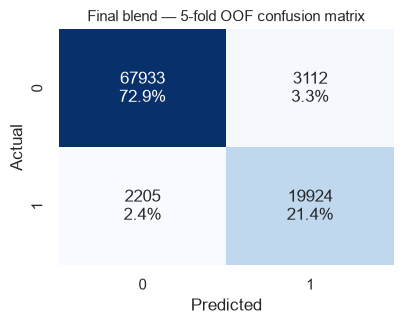

In [40]:
final_perf = pd.concat([
    performance(y, oof_lgb, "LightGBM (tuned)"), performance(y, oof_xgb, "XGBoost"),
    performance(y, oof_cat, "CatBoost"), performance(y, oof_blend, "Blend (final)")]).round(4)
display(final_perf)
plot_cm(y, oof_blend, "Final blend — 5-fold OOF confusion matrix")

## Feature importance

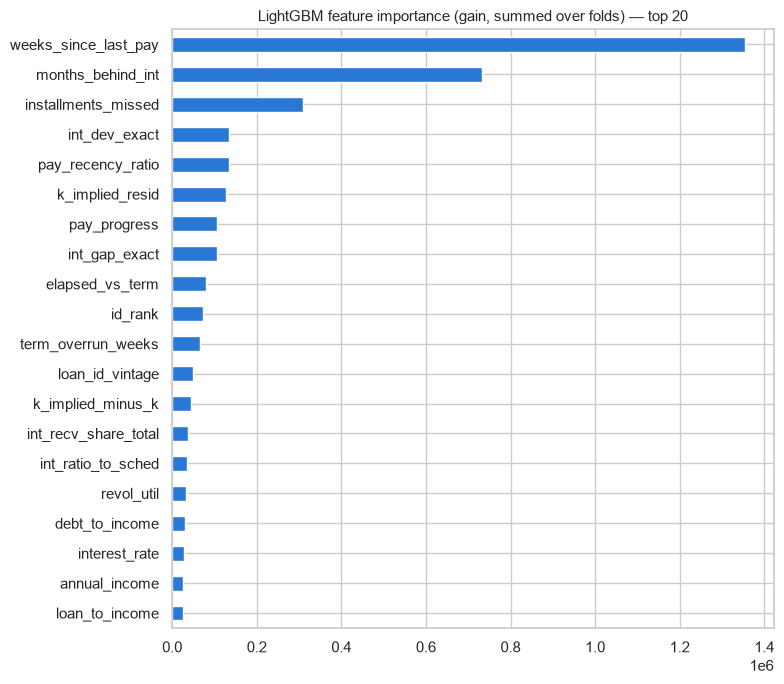

In [41]:
imp = pd.Series(sum(m.feature_importance("gain") for m in lgb_models), index=X.columns).sort_values(ascending=False)
plt.figure(figsize=(8, 7))
imp.head(20)[::-1].plot(kind="barh", color=PALETTE[0])
plt.title("LightGBM feature importance (gain, summed over folds) — top 20"); plt.tight_layout(); plt.show()

**Observations**
* The top of the ranking is **entirely engineered payment-behaviour features**: `weeks_since_last_pay`, `months_behind_int`, `installments_missed`, the interest-vs-schedule deviations, and the vintage estimate.
* Raw application-time attributes (grade, DTI, income, purpose) appear far down the list — they matter, but an order of magnitude less than *observed repayment behaviour relative to the contract*.

# **Robustness and Validity Checks**

Three checks establish what the headline number does and does not mean.

**1. Vintage (ID-cohort) holdout — can the model extrapolate to unseen vintages?** Train on 4 of 5 vintage groups, score the held-out one.

In [42]:
groups = pd.qcut(train.ID, 5, labels=False).values
oof_g = np.zeros(len(X))
for a, b in GroupKFold(5).split(X, y, groups):
    m = lgb.train(LGB_PARAMS, lgb.Dataset(X.iloc[a], y[a]), 1000)
    oof_g[b] = m.predict(X.iloc[b])
cohort = pd.DataFrame({"group": groups, "correct": (oof_g > 0.5) == y, "default": y})
summary = cohort.groupby("group").agg(accuracy=("correct", "mean"), default_rate=("default", "mean"), n=("correct", "size")).round(3)
print(f"vintage-holdout overall accuracy: {(oof_g > 0.5).__eq__(y).mean():.4f}  (random-CV: {acc(oof_blend):.4f})")
display(summary)

vintage-holdout overall accuracy: 0.9127  (random-CV: 0.9429)


,accuracy,default_rate,n
group,,,
0,0.731,0.635,18635
1,0.916,0.307,18635
2,0.954,0.162,18634
3,0.975,0.066,18635
4,0.988,0.017,18635


* Accuracy drops to ~0.92 overall and to ~0.75 on the oldest vintage (where the default prevalence is also most extreme). The model **depends on exposure-time patterns and does not extrapolate to unseen vintages** — fine for this competition (train and test share the same vintage range; adversarial validation AUC = 0.50), but a deployment would need vintage-matched training data.

**2. Origination-time-only model — how much of the signal is post-origination?** Drop every payment/vintage/ID-derived column and retrain.

In [43]:
post_cols = [c for c in X.columns if c in ["last_week_pay", "interest_receive", "total_current_balance",
             "loan_id_vintage", "id_rank", "weeks_elapsed_est", "weeks_since_last_pay", "pay_recency_ratio",
             "term_overrun_weeks", "elapsed_vs_term", "loan_should_be_done", "pay_progress", "months_paid",
             "interest_sched_to_date", "int_ratio_to_sched", "int_gap_to_sched", "int_recv_per_loan",
             "int_recv_per_week", "int_recv_per_rate", "int_recv_share_total", "bal_to_income", "lwp_missing",
             "tcb_missing", "k_int", "int_dev_exact", "int_gap_exact", "k_implied", "k_implied_resid",
             "k_implied_minus_k", "months_elapsed_int", "installments_missed", "months_behind_int"]]
X_orig = X.drop(columns=post_cols)
oof_orig, _, _ = cv_lgb(X_orig, y)
print(f"origination-time features only ({X_orig.shape[1]} cols): OOF accuracy = {acc(oof_orig):.4f}")
print(f"full snapshot feature set: OOF accuracy = {acc(oof_blend):.4f}")
print(f"majority-class baseline: {max(y.mean(), 1 - y.mean()):.4f}")

origination-time features only (24 cols): OOF accuracy = 0.8239
full snapshot feature set: OOF accuracy = 0.9429
majority-class baseline: 0.7625


* With only application-time information, accuracy falls to ~82% — above the 76% majority baseline, so application data carries real signal, but far short of the 94%+ achieved with the snapshot features: **the bulk of the predictive power comes from post-origination repayment behaviour**. This quantifies the leakage boundary: the competition features describe a servicing snapshot, and any claim about *approving* applicants must rest on the (much weaker) origination-time model.

**3. Where do the remaining errors live?**

In [44]:
err = (oof_blend > 0.5) != y
seg = pd.DataFrame({"missed": X["installments_missed"], "err": err, "y": y})
g = seg.groupby(pd.cut(seg.missed, [-100, 0, 1, 3, 12, 100]), observed=True).agg(
    n=("err", "size"), error_rate=("err", "mean"), default_rate=("y", "mean")).round(3)
display(g)

,n,error_rate,default_rate
missed,,,
"(-100, 0]",26120,0.011,0.019
"(0, 1]",36820,0.017,0.031
"(1, 3]",5736,0.113,0.394
"(3, 12]",11680,0.103,0.725
"(12, 100]",12818,0.201,0.761


* Errors concentrate in loans that stopped paying **more than ~12 installments ago** (error rate ~20%): once payments stop long enough, a **fully prepaid loan and a charged-off loan look identical** in these columns. Segment-specific thresholds and a cross-fitted residual model were both tested and failed a McNemar test — this ambiguity is a *data* limitation (no payoff-vs-charge-off marker), not a modelling one.

# **Prediction on the Test Set and Submission**

In [45]:
test_blend = best_w[0] * test_lgb + best_w[1] * test_cat + best_w[2] * test_xgb
submission = pd.DataFrame({"ID": test["ID"], "default": (test_blend > 0.5).astype(int)})
submission.to_csv("submission_final.csv", index=False)
print(submission.shape, "| predicted default rate:", submission["default"].mean().round(4),
      "| train default rate:", y.mean().round(4))
submission.head()

(39933, 2) | predicted default rate: 0.2528 | train default rate: 0.2375


,ID,default
0,4855329,1
1,66862420,0
2,3637416,0
3,53682249,0
4,53937165,0


* The file has exactly 39,933 rows with columns `ID` and `default`, as required. The predicted default rate (~25%) is consistent with the training prevalence given the test set's identical vintage mix.
* **Best leaderboard result: 0.9412 accuracy** (CV 0.9440 for the final 10-fold multi-seed blend; the ~0.25 pt CV-to-leaderboard offset is consistent across all our submissions). The final rank is decided when the hackathon closes.

# **Business Insights and Recommendations**

## Insights

* **Default risk in this portfolio is overwhelmingly a *behavioural* signal, not an application-time one.** A borrower's position relative to their amortisation schedule — installments missed, interest received versus interest scheduled, time since the last payment — explains almost all predictable default. Application-time attributes alone (grade, income, DTI, purpose) reach only ~82% accuracy on this snapshot task — meaningfully above the 76% majority baseline, but far below the 94%+ that repayment behaviour delivers.
* **Raw correlations deceived; cohort structure ruled.** Grade A appeared *riskier* than grade E, and low DTI appeared riskier than high DTI — both artifacts of older vintages having had more exposure time to default. After conditioning on vintage, grade ordering is normal (A 5.0% → G 8.2% in recent vintages). Any portfolio analysis at DHDL must control for loan age before comparing segments.
* **Missingness is a signal.** Missing account-balance fields mark an old reporting cohort with ~80% default; missing payment history marks brand-new loans with ~0%. Treating these as "data problems to impute away" would have destroyed information.
* **The earliest reliable alarm is 2–3 missed installments.** Default rates jump from ~3% (≤1 behind) to ~61% (2–3 behind) to ~75%+ (12+ behind). The transition zone of 1–3 missed installments is where intervention can still change outcomes.
* **A structural blind spot:** once payments have stopped for a year or more, prepaid and charged-off loans are indistinguishable in these fields; that is where the model's remaining errors concentrate.

## Recommendations

* **Deploy the model as a monthly servicing-book triage score**, not an origination score. Rank live loans by predicted default probability and route the 1–3-installments-behind band to proactive outreach (restructuring offers, payment plans) while recovery is still likely.
* **Build an early-warning trigger on schedule deviation.** The interest-received-vs-scheduled gap degrades *before* a loan is formally delinquent; a simple threshold alert on this engineered quantity would surface stress earlier than bucket-based DPD reporting.
* **Fix the data pipeline for the next iteration:** record a loan status field distinguishing *prepaid / matured / restructured / charged-off* (removes the model's biggest error source), store explicit origination and payment dates rather than leaving vintage implicit in the ID sequence, and unify the balance-reporting regimes that currently show up as cohort-wide missingness.
* **For origination decisions, collect richer application-time data** (bureau scores, verified income trails): this analysis demonstrates the current application-time fields cannot support accurate approval-stage default prediction on their own.
* **Re-train on a vintage-matched window before any production use.** The cohort-holdout test shows accuracy falls to ~75% on vintage ranges absent from training; the model must always be trained on loans whose age distribution matches the book it scores.